<a href="https://colab.research.google.com/github/shyamprasadg22/FDS-Experiments/blob/main/ShyamprasadG_250701711_Exp16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

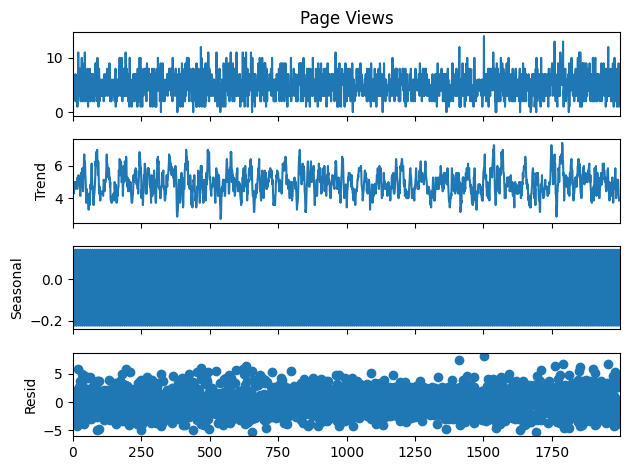

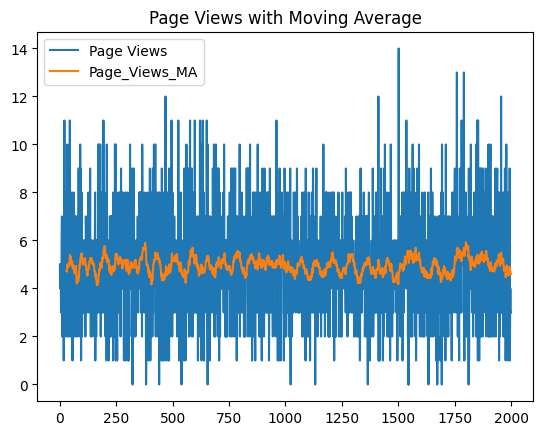

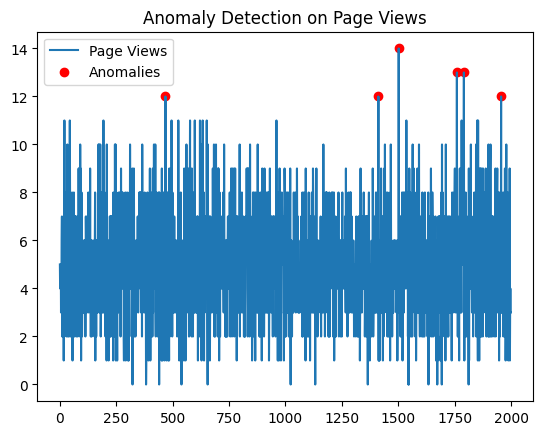

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Load dataset
data = pd.read_csv('/content/website_wata.csv')

# Time Series Decomposition (assuming a dummy daily period since there is no Date column)
# We'll use a period of 7 to represent weekly seasonality if rows represent daily sequential records
try:
    decomposition = seasonal_decompose(data['Page Views'], model='additive', period=7)
    decomposition.plot()
    plt.show()
except Exception as e:
    print("Error in decomposition:", e)

# Moving Average
data['Page_Views_MA'] = data['Page Views'].rolling(window=30).mean()
data[['Page Views', 'Page_Views_MA']].plot()
plt.title('Page Views with Moving Average')
plt.show()

# Anomaly Detection
data['Page_Views_Z'] = (data['Page Views'] - data['Page Views'].mean()) / data['Page Views'].std()
anomalies = data[data['Page_Views_Z'].abs() > 3]

plt.plot(data.index, data['Page Views'], label='Page Views')
plt.scatter(anomalies.index, anomalies['Page Views'], color='red', label='Anomalies')
plt.legend()
plt.title('Anomaly Detection on Page Views')
plt.show()